# 02 - Analyse des sous-bandes ondelettes

Ce notebook présente les décompositions en ondelettes utilisées par le Wavelet-Guided U-Net :
sous-bandes LL, LH, HL et HH, reconstruction inverse, différence entre transformée décimée (DWT) et
stationnaire (SWT), et comportement des sous-bandes quand la résolution de l'image diminue.

Les transformées sont calculées avec PyWavelets en prétraitement : elles ne sont ni apprises ni
différentiables, et elles ne sont jamais appliquées aux masques.

In [1]:
import os, sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.width", 140)
from src.utils import load_config, resolve
from src.data.msd import load_case
from src.data.splits import load_split
from src.wavelets.transforms import dwt2_subbands, idwt2_reconstruct, swt2_subbands, multilevel_dwt, SUBBANDS
cfg = load_config("configs/data.yaml")
split = load_split(resolve(cfg["split"]["file"]), "subset")
case = load_case(resolve(cfg["dataset"]["raw_dir"]), split["train"][0])
z = int(np.argmax((case.label == 1).sum(axis=(1, 2))))
image = case.image[z].astype(np.float64)
print(case.case_id, "coupe", z, image.shape)

hepaticvessel_245 coupe 50 (512, 512)


## 1. Sous-bandes de Haar

Avec la convention de PyWavelets (`dwt2` retourne `cA, (cH, cV, cD)`), j'appelle LL l'approximation,
LH les détails horizontaux, HL les détails verticaux et HH les détails diagonaux. La DWT divise la
taille par deux à chaque niveau ; la SWT (non décimée) garde la taille de l'image.

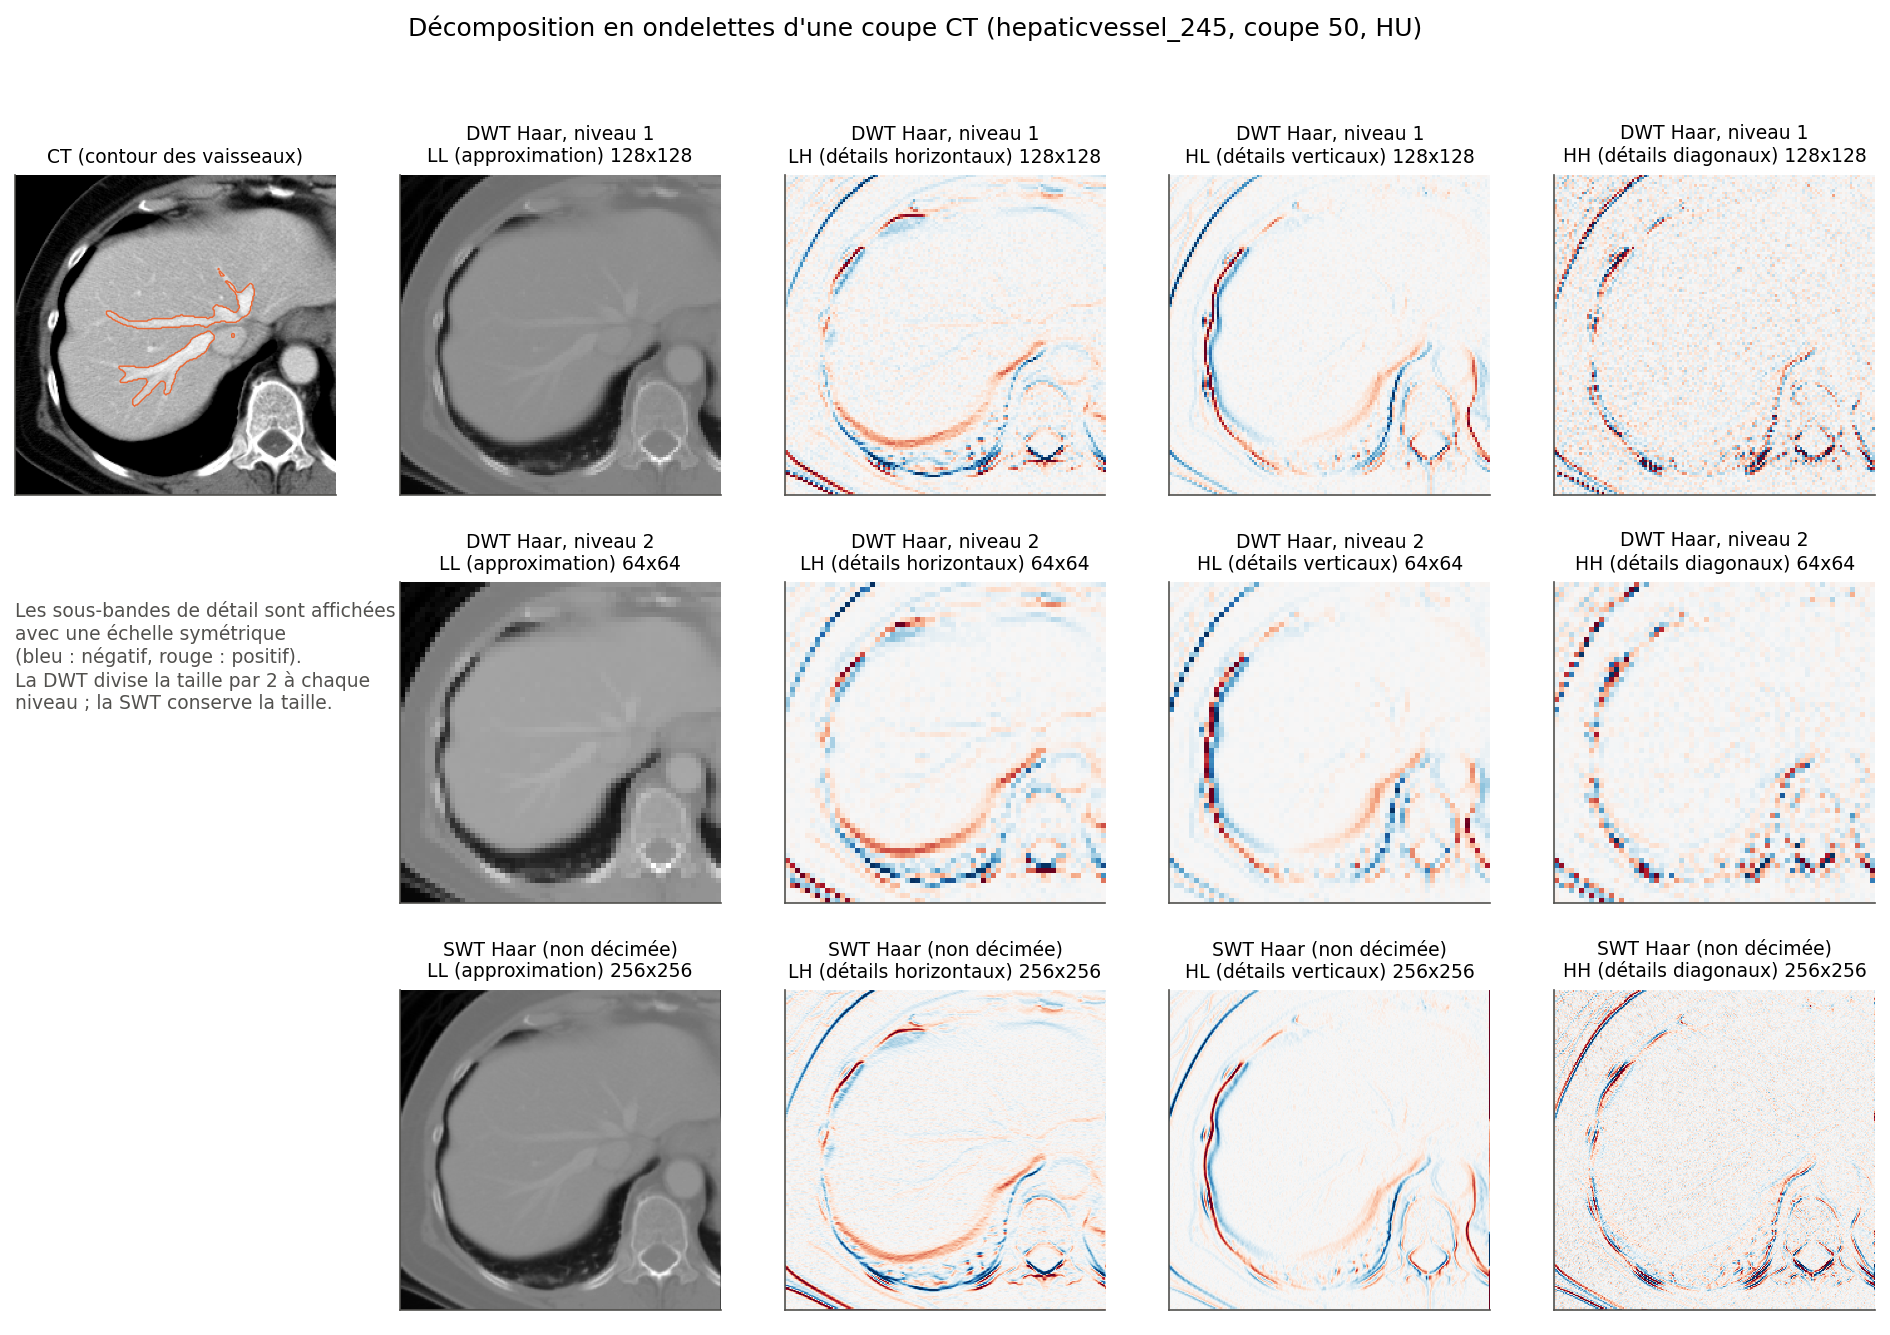

In [2]:
display(Image("results/figures/wavelets/sous_bandes_haar.png"))

In [3]:
for name, bands in [("DWT niveau 1", dwt2_subbands(image)), ("SWT", swt2_subbands(image))]:
    print(name, {k: v.shape for k, v in bands.items()})
print("Tailles des niveaux DWT (alignées sur les étages du U-Net) :", [l["LL"].shape for l in multilevel_dwt(image, 4)])

DWT niveau 1 {'LL': (256, 256), 'LH': (256, 256), 'HL': (256, 256), 'HH': (256, 256)}
SWT {'LL': (512, 512), 'LH': (512, 512), 'HL': (512, 512), 'HH': (512, 512)}
Tailles des niveaux DWT (alignées sur les étages du U-Net) : [(256, 256), (128, 128), (64, 64), (32, 32)]


## 2. Reconstruction inverse

La transformée inverse doit retrouver l'image d'origine à la précision numérique près.

In [4]:
recon = pd.read_csv("results/metrics/wavelet_reconstruction.csv")
recon

,transform,wavelet,max_abs_error_hu,n_slices
0,DWT,haar,6.821210e-13,12
1,SWT,haar,6.821210e-13,12
2,DWT,db2,1.023182e-12,12
3,SWT,db2,6.821210e-13,12
4,DWT,db4,1.023182e-12,12
5,SWT,db4,6.821210e-13,12


## 3. Haar et Daubechies 2

Les filtres de Daubechies 2 sont plus longs (4 coefficients) : les sous-bandes sont plus lisses et
dépendent du mode d'extension aux bords.

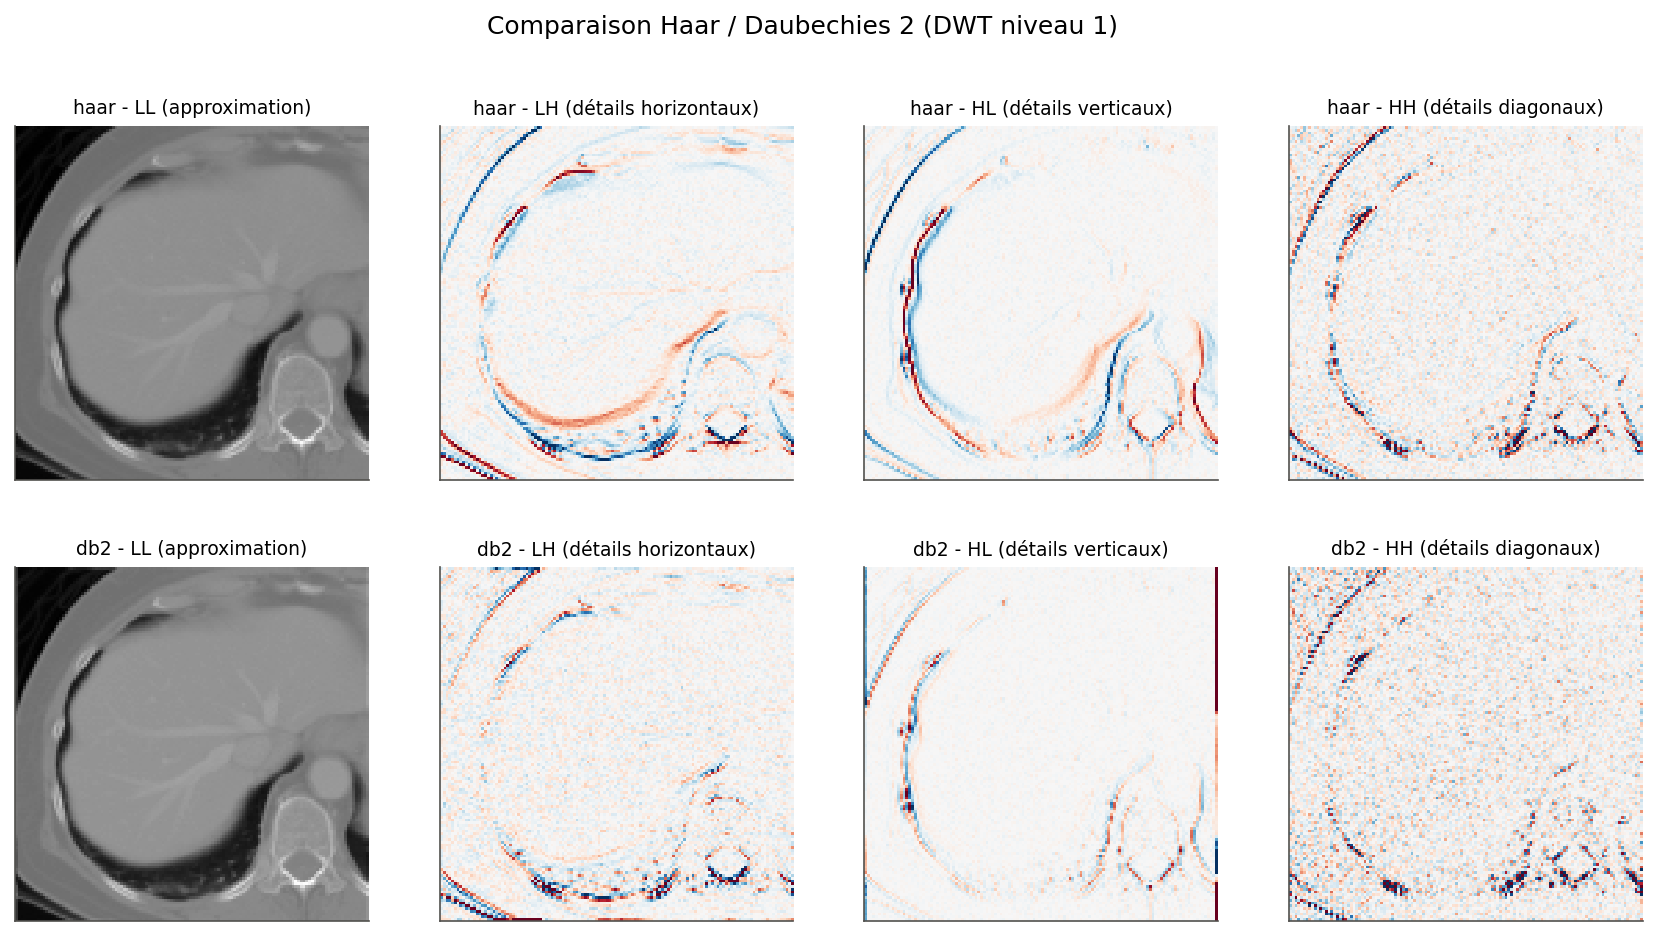

In [5]:
display(Image("results/figures/wavelets/haar_vs_db2.png"))

## 4. Information portée par les sous-bandes autour des vaisseaux

J'ai mesuré l'amplitude moyenne des coefficients SWT Haar (sur le CT normalisé) dans les vaisseaux et
dans un anneau de 5 pixels autour, pour les images originales et sous-échantillonnées d'un facteur 2
ou 4 (puis ramenées à la grille d'origine).

In [6]:
energy = pd.read_csv("results/metrics/wavelet_band_energy.csv")
summary = energy.groupby("condition").mean(numeric_only=True).drop(columns="slice").reindex(["original", "down_x2", "down_x4"])
summary.T.round(4)

condition,original,down_x2,down_x4
LL_vessel,2.1756,2.1032,1.8977
LL_ring,1.2454,1.2131,1.1920
LH_vessel,0.3122,0.1510,0.0862
LH_ring,0.3099,0.1442,0.0804
HL_vessel,0.2433,0.1345,0.0793
HL_ring,0.2416,0.1295,0.0775
HH_vessel,0.1641,0.0355,0.0097
HH_ring,0.1638,0.0364,0.0092


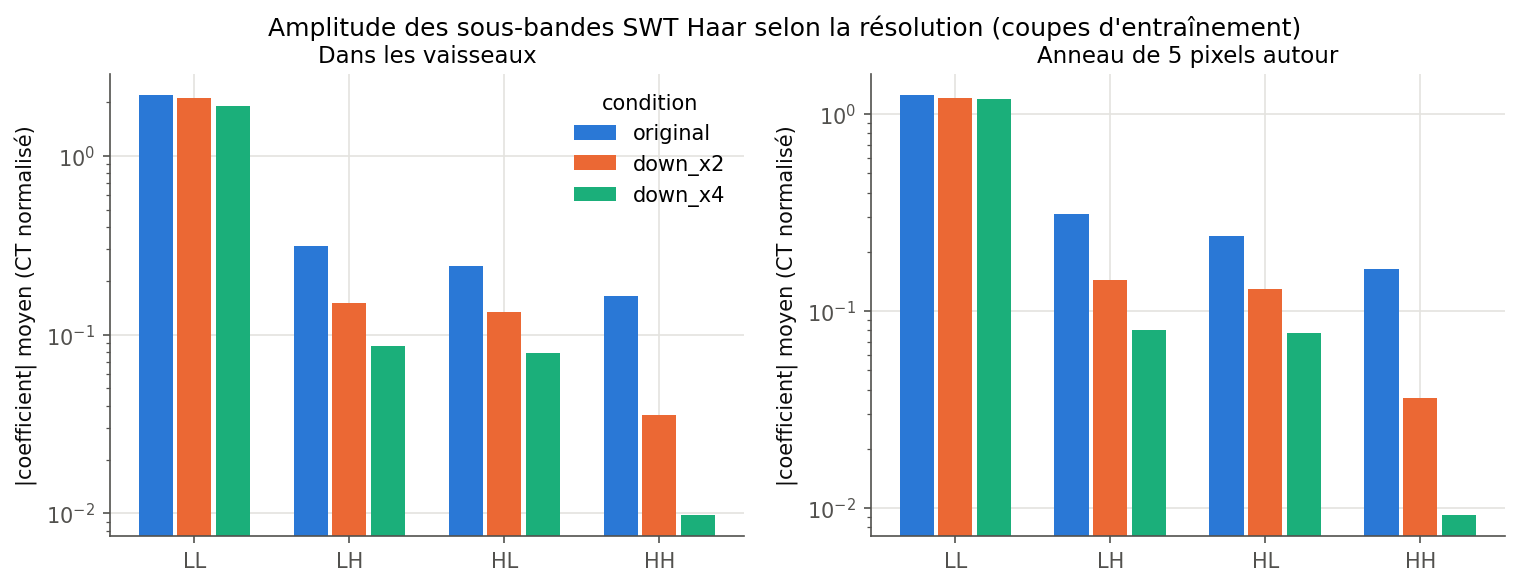

In [7]:
display(Image("results/figures/wavelets/energie_sous_bandes_degradations.png"))

Deux observations :

- au niveau 1, l'amplitude moyenne des détails (LH, HL, HH) est presque la même dans les vaisseaux
  et dans l'anneau qui les entoure. À cette échelle très fine, les coefficients de détail
  contiennent surtout le bruit de l'image et les contours forts (bord du corps, os), et pas un
  signal propre aux vaisseaux ;
- le sous-échantillonnage fait presque disparaître ces détails : HH perd environ 78 % de son
  amplitude au facteur 2 et 94 % au facteur 4, alors que LL change peu. Sur des images dégradées,
  les canaux de détail donnés aux modèles ondelettes ont donc une distribution très différente de
  celle vue à l'entraînement.

## 5. Entrées du réseau

Pour le modèle « entrée », les quatre sous-bandes SWT sont standardisées avec des statistiques
calculées sur les coupes d'entraînement, puis concaténées à la coupe CT (5 canaux). Pour le modèle
« multi-échelle », les sous-bandes DWT du niveau k sont concaténées aux caractéristiques de l'étage k
de l'encodeur (H/2 puis H/4).

Entrée (SWT) : (5, 512, 512) moyennes par canal : [-1.404  0.145 -0.     0.    -0.   ] écarts-types : [1.173 1.227 1.003 0.986 0.917]
Entrée (multi-échelle) : (1, 512, 512) injections : [(4, 256, 256), (4, 128, 128)]


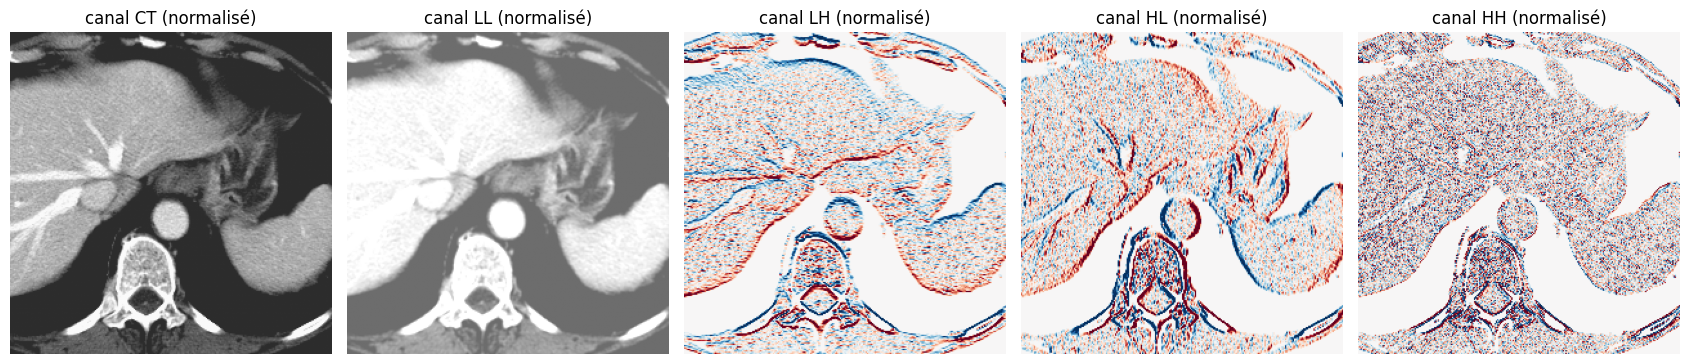

In [8]:
from src.training.trainer import build_wavelet
from src.preprocessing.pipeline import load_processed
from src.data.dataset2d import make_inputs
proc = load_processed(resolve(cfg["preprocessing"]["processed_dir"]) / case.case_id)
sl = np.asarray(proc["image"][z], np.float32)
w_in = build_wavelet({"wavelet_mode": "swt", "wavelet": "haar"}, resolve(cfg["preprocessing"]["wavelet_stats_file"]))
w_ms = build_wavelet({"wavelet_mode": "dwt_multilevel", "wavelet": "haar", "wavelet_levels": 2}, resolve(cfg["preprocessing"]["wavelet_stats_file"]))
x_in, _ = make_inputs(sl, w_in)
x_ms, inj = make_inputs(sl, w_ms)
print("Entrée (SWT) :", x_in.shape, "moyennes par canal :", x_in.reshape(5, -1).mean(1).round(3), "écarts-types :", x_in.reshape(5, -1).std(1).round(3))
print("Entrée (multi-échelle) :", x_ms.shape, "injections :", [a.shape for a in inj])
fig, axes = plt.subplots(1, 5, figsize=(17, 3.6))
for ax, ch, name in zip(axes, x_in, ["CT"] + list(SUBBANDS)):
    ax.imshow(ch[150:400, 150:400], cmap="gray" if name in ("CT", "LL") else "RdBu_r", vmin=-3, vmax=3)
    ax.set_title(f"canal {name} (normalisé)"); ax.axis("off")
plt.tight_layout(); plt.show()

## Bilan

La décomposition et la reconstruction sont exactes à la précision numérique près, et les
dimensions des sous-bandes correspondent aux étages du U-Net. L'analyse des amplitudes suggère
toutefois que les détails de Haar au niveau 1 apportent peu d'information spécifique aux vaisseaux
par rapport à ce qu'un réseau convolutif peut déjà calculer à partir du CT (une convolution 3 x 3
peut reproduire un filtre de Haar 2 x 2). Il ne faut donc pas s'attendre a priori à un gain
important : c'est ce que la comparaison des modèles doit vérifier (notebook 03).